In [ ]:
import numpy as np
from scipy.optimize import curve_fit
from astropy import units
from functools import partial
from matplotlib import pyplot as plt
from IPython.display import Image
%matplotlib notebook

In [ ]:
def quarterwave_model(psi, q, u, v, zero=None):
    """Compute polarimetry z(psi) model for quarter wavelength retarder.

    Z(psi) = Q*cos(2psi)**2 + U*sin(2psi)*cos(2psi) - V*sin(2psi)

    Parameters
    ----------
    psi: array_like
        Array of retarder positions in degrees.
    q, u, v: float
        Stokes parameters
    zero: float
        Zero position of the retarder in degrees.

    Return
    ------
    z: array_like
        Array of polarimetry values.
    """
    if zero is not None:
        psi = psi+zero
    psi = np.radians(psi)
    psi2 = 2*psi
    zi = q*(np.cos(psi2)**2) + u*np.sin(psi2)*np.cos(psi2) - v*np.sin(psi2)
    return zi


def halfwave_model(psi, q, u, zero=None):
    """Compute polarimetry z(psi) model for half wavelength retarder.

    Z(psi) = Q*cos(4*psi) + U*sin(4*psi)

    Parameters
    ----------
    psi: array_like
        Array of retarder positions in degrees.
    q, u: float
        Stokes parameters
    zero: float (optional)
        Zero angle of the retarder position.

    Return
    ------
    z: array_like
        Array of polarimetry values.
    """
    if zero is not None:
        psi = psi+zero
    psi = np.radians(psi)
    zi = q*np.cos(4*psi) + u*np.sin(4*psi)
    return zi


def get_zi(psi, q, u, v=None, zero=0):
    """Get z(i) fluxes for each position."""
    if v is None:
        return halfwave_model(psi, q, u, zero)
    else:
        return quarterwave_model(psi, q, u, v, zero)


def get_flux_oe(flux, psi, k, q, u, v=None, zero=0):
    """Get ordinary and extraordinary fluxes."""
    zi = get_zi(psi, q, u, v, zero)
    fo = flux*(1+zi)/2
    fe = flux*(1-zi)/2
    return fo, fe/k

# Quarter-Wave

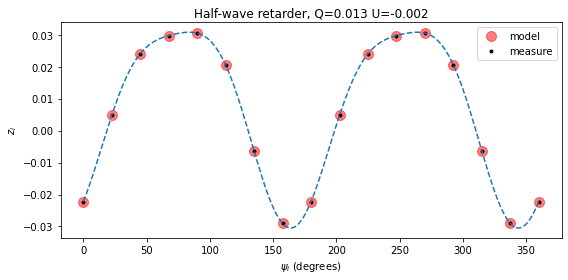

In [ ]:
# Quarter-wave
q = 0.0130
u = -0.0021
v = 0.03044

pos = np.arange(0, 360.5, 22.5) * units.degree
line = np.arange(0, 360.5, 0.5) * units.degree

zi_predicted = get_zi(pos, q, u, v, zero=60*units.degree)
fo, fe = get_flux_oe(1e5, pos, 1.0, q, u, v, zero=60*units.degree)
zi_measure = (fo - fe)/(fo + fe)

plt.figure(figsize=(8, 4))
plt.plot(pos, zi_predicted, 'ro', alpha=0.5, ms=10, label='model')
plt.plot(pos, zi_measure, 'k.', label='measure')
plt.plot(line, get_zi(line, q, u, v, zero=60*units.degree), '--')
plt.xlabel(r'$\psi_i$ (degrees)')
plt.ylabel(r'$z_i$')
plt.title(f'Half-wave retarder, Q={q:.3f} U={u:.3f}')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
q = 0.0130
u = -0.0021
v = 0.03044
zero = 60
pos = np.arange(0, 360, 22.5)
zi = quarterwave_model(pos, q=q, u=u, v=v, zero=zero)

fit = curve_fit(quarterwave_model, pos, zi, bounds=([-1, -1, -1, 0], [1, 1, 1, 180]), method='trf')
# fit = curve_fit(quarterwave_model, pos, zi, method='lm')

In [ ]:
qfit, ufit, vfit, zfit = fit[0]
print(fit)

(array([ 1.300e-02, -2.100e-03,  3.044e-02,  6.000e+01]), array([[7.78082985e-33, 2.28158807e-34, 4.02824815e-42, 2.51394942e-31],
       [2.28158807e-34, 2.75428677e-32, 7.35539943e-41, 4.66876269e-30],
       [4.02824815e-42, 7.35539943e-41, 5.82640828e-33, 8.12317167e-38],
       [2.51394942e-31, 4.66876269e-30, 8.12317167e-38, 5.14423851e-27]]))


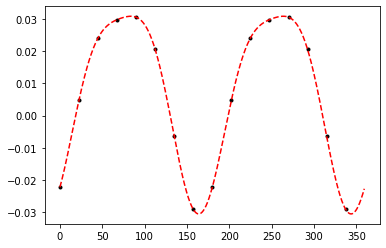

In [ ]:
plt.figure()
plt.plot(pos, zi, 'ko', ms=3)
line = np.arange(0, 360, 0.5)
plt.plot(line, quarterwave_model(line, qfit, ufit, vfit, zfit), 'r--')
plt.show()

# Half-Wave

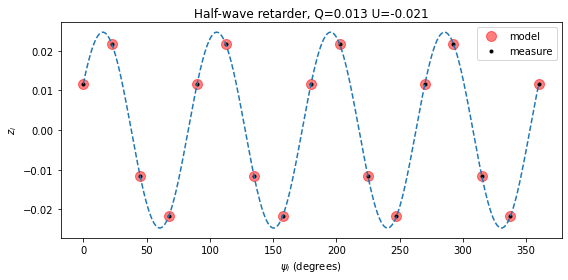

In [ ]:
q = 0.0130
u = -0.021
zero = 60*units.degree

pos = np.arange(0, 360.5, 22.5) * units.degree
line = np.arange(0, 360.5, 0.5) * units.degree

zi_predicted = get_zi(pos, q, u, zero=zero)
fo, fe = get_flux_oe(1e5, pos, 1.0, q, u, zero=zero)
zi_measure = (fo - fe)/(fo + fe)

plt.figure(figsize=(8, 4))
plt.plot(pos, zi_predicted, 'ro', alpha=0.5, ms=10, label='model')
plt.plot(pos, zi_measure, 'k.', label='measure')
plt.plot(line, get_zi(line, q, u, zero=zero), '--')
plt.xlabel(r'$\psi_i$ (degrees)')
plt.ylabel(r'$z_i$')
plt.title(f'Half-wave retarder, Q={q:.3f} U={u:.3f}')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
q = 0.0130
u = -0.021
zero = 60
pos = np.arange(0, 360.5, 22.5)
line = np.arange(0, 360.5, 0.5)

zi = halfwave_model(pos, q=q, u=u, zero=zero)
model = partial(halfwave_model, zero=zero)

fit = curve_fit(model, pos, zi, bounds=([-1, -1], [1, 1]), method='trf')

In [ ]:
qfit, ufit = fit[0]
print(fit)

(array([ 0.013, -0.021]), array([[ 8.45463382e-29, -4.18395867e-30],
       [-4.18395867e-30,  7.97151189e-29]]))


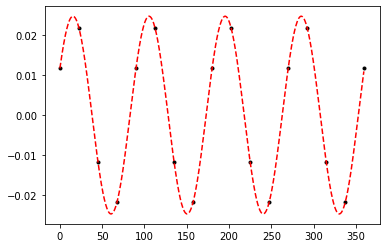

In [ ]:
plt.figure()
plt.plot(pos, zi, 'ko', ms=3)
line = np.arange(0, 360, 0.5)
plt.plot(line, halfwave_model(line, qfit, ufit, zero), 'r--')
plt.show()

# Real Data

Extracted from Claudia's graph.

In [ ]:
#polar_circular.eps file
psi = np.arange(8)*22.5
zi = np.array([-0.031875, 0.0101, 0.0218, 0.0310, 0.0496, 0.01593, -0.009687, -0.00484375])

fit = curve_fit(quarterwave_model, psi, zi, bounds=([-1, -1, -1, 0], [1, 1, 1, 90]), method='trf')

In [ ]:
q, u, v, zero = fit[0]
q_err, u_err, v_err, zero_err = np.sqrt(np.diagonal(fit[1]))

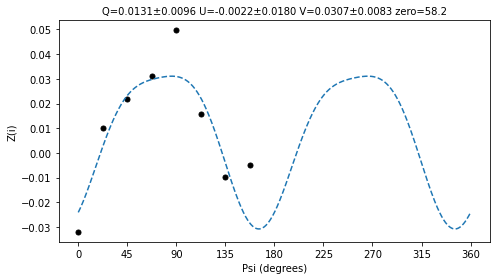

In [ ]:
line = np.arange(0, 360, 0.5)
plt.figure(figsize=(7, 4))
plt.plot(psi, zi, 'ko', ms=5)
plt.plot(line, quarterwave_model(line, q, u, v, zero), '--')
plt.xticks(np.arange(0, 361, 45))
plt.xlabel('Psi (degrees)')
plt.ylabel('Z(i)')
plt.title(f'Q={q:.4f}±{q_err:.4f} U={u:.4f}±{u_err:.4f} V={v:.4f}±{v_err:.4f} zero={zero:.1f}', fontsize=10)
plt.tight_layout()
plt.show()

<img src='https://drive.google.com/uc?id=1vNOxr8sXDIMDXedi0EuoRD7o-EtUhLRV' width=500>

In [ ]:
#padrao.eps file
psi = np.arange(16)*22.5
zi = [0.0040659, -0.0143956, -0.019120, 0.0021978, 0.0083516, -0.012857, -0.022087, 0.0007692, 0.00736263,
      -0.015714, -0.0224175, -0.0001098, 0.0050549, -0.015934, -0.021318, -0.0027472]

fit = curve_fit(quarterwave_model, psi, zi, bounds=([-1, -1, -1, 0], [1, 1, 1, 90]), method='trf')

In [ ]:
q, u, v, zero = fit[0]
q_err, u_err, v_err, zero_err = np.sqrt(np.diagonal(fit[1]))

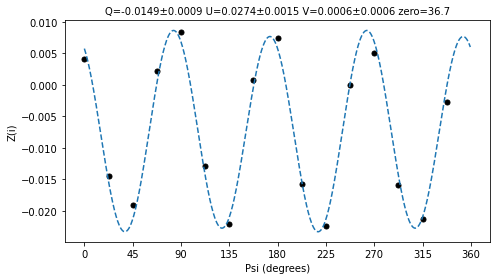

In [ ]:
line = np.arange(0, 360, 0.5)
plt.figure(figsize=(7, 4))
plt.plot(psi, zi, 'ko', ms=5)
plt.plot(line, quarterwave_model(line, q, u, v, zero), '--')
plt.xticks(np.arange(0, 361, 45))
plt.xlabel('Psi (degrees)')
plt.ylabel('Z(i)')
plt.title(f'Q={q:.4f}±{q_err:.4f} U={u:.4f}±{u_err:.4f} V={v:.4f}±{v_err:.4f} zero={zero:.1f}', fontsize=10)
plt.tight_layout()
plt.show()

<img src='https://drive.google.com/uc?id=1BcNU1SsPY709YnsX4F4VwyKuf31pX16a' width=500>

In [ ]:
# padrao_l2.eps file
psi = (-np.arange(16)*22.5) % 360  # novo módulo, pós 2007
zi = np.array([0.01003, -0.0252, -0.00468, 0.02639, 0.00684, -0.02938, -0.007049, 0.02794, 0.00900,
               -0.02763293, -0.009313, 0.02506, 0.007255, -0.02608, -0.00674, 0.023722])

model = partial(halfwave_model, zero=None)
fit = curve_fit(model, psi, zi, bounds=([-1, -1], [1, 1]), method='trf')

In [ ]:
q, u = fit[0]
q_err, u_err = np.sqrt(np.diagonal(fit[1]))

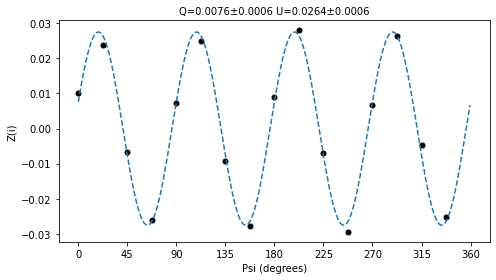

In [ ]:
line = np.arange(0, 360, 0.5)
plt.figure(figsize=(7, 4))
plt.plot(psi, zi, 'ko', ms=5)
plt.plot(line, halfwave_model(line, q, u), '--')
plt.xticks(np.arange(0, 361, 45))
plt.xlabel('Psi (degrees)')
plt.ylabel('Z(i)')
plt.title(f'Q={q:.4f}±{q_err:.4f} U={u:.4f}±{u_err:.4f}', fontsize=10)
plt.tight_layout()
plt.show()

<img src='https://drive.google.com/uc?id=1HpnxVQmNnddFJkNeMv1L1yOkUBYjYiYs' width=500>

# Padrão polarizada do Fernando

In [ ]:
# dados padrão polarizada
psi = np.arange(16)*22.5
zi = np.array([-0.01558, 0.00668, 0.05198, 0.02872,
               -0.04724, 0.00343, 0.02217, 0.03445,
               0.01304, -0.01295, 0.02540, 0.05854,
               0.01267, 0.00616, 0.05057, 0.05887])
zero = 48
model = partial(quarterwave_model, zero=zero)
fit = curve_fit(model, psi, zi, bounds=([-1, -1, -1], [1, 1, 1]), method='trf')

In [ ]:
q, u, v = fit[0]
q_err, u_err, v_err = np.sqrt(np.diagonal(fit[1]))
print(fit[1])

[[ 5.72196622e-05 -2.14878080e-14  8.79428710e-16]
 [-2.14878080e-14  1.71658986e-04  2.84346549e-15]
 [ 8.79428710e-16  2.84346549e-15  4.29147466e-05]]


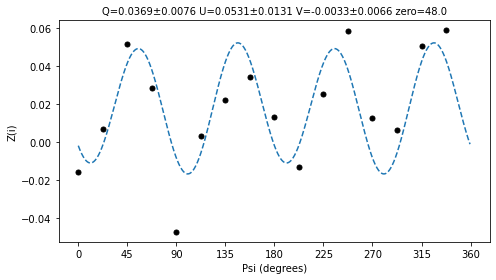

In [ ]:
line = np.arange(0, 360, 0.5)
plt.figure(figsize=(7, 4))
plt.plot(psi, zi, 'ko', ms=5)
plt.plot(line, quarterwave_model(line, q, u, v, zero), '--')
plt.xticks(np.arange(0, 361, 45))
plt.xlabel('Psi (degrees)')
plt.ylabel('Z(i)')
plt.title(f'Q={q:.4f}±{q_err:.4f} U={u:.4f}±{u_err:.4f} V={v:.4f}±{v_err:.4f} zero={zero:.1f}', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
resultado_claudia ={'v': -0.003260,
                    'sigmav': 0.006551,
                    'q': 0.036931,
                    'u': -0.053076,
                    'sigma': 0.011590,
                    'p': 0.064661,
                    'theta': 152.4,
                    'sigma_theor': 0.000336,
                    'rms': 0.0185287}